# 02 · Trends, ENSO and return periods

Three questions:

1. Is Jamaica seeing **more**, or **stronger**, storms than in the past?
2. Does **ENSO** (El Niño / La Niña) shift the odds in a given season?
3. How often should we **expect** a hurricane or major hurricane near the island?

A caution on data quality: before satellites (1966) and aircraft reconnaissance (1944), weak or short-lived storms over open water were undercounted. Storms that hit a populated island like Jamaica were usually recorded, but intensity estimates before about 1950 are rough. Where it matters, I report results separately for the modern era.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from jhurricane import config, plotting as P

P.set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

storms = pd.read_csv(config.DATA_PROCESSED / "storms.csv", parse_dates=["closest_datetime"])
seasons = pd.read_csv(config.DATA_PROCESSED / "seasons.csv")
points = pd.read_csv(config.DATA_PROCESSED / "track_points.csv", parse_dates=["datetime"])
impacts = pd.read_csv(config.DATA_PROCESSED / "impacts.csv")
near = storms[storms["is_near"]].copy()

In [2]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

seasons["hurricanes_near"] = seasons["hurricanes_near"].astype(int)
seasons["majors_near"] = seasons["majors_near"].astype(int)
seasons["ts_only"] = seasons["storms_near"] - seasons["hurricanes_near"]
seasons["hu_minor"] = seasons["hurricanes_near"] - seasons["majors_near"]

## 1 · Counts per decade

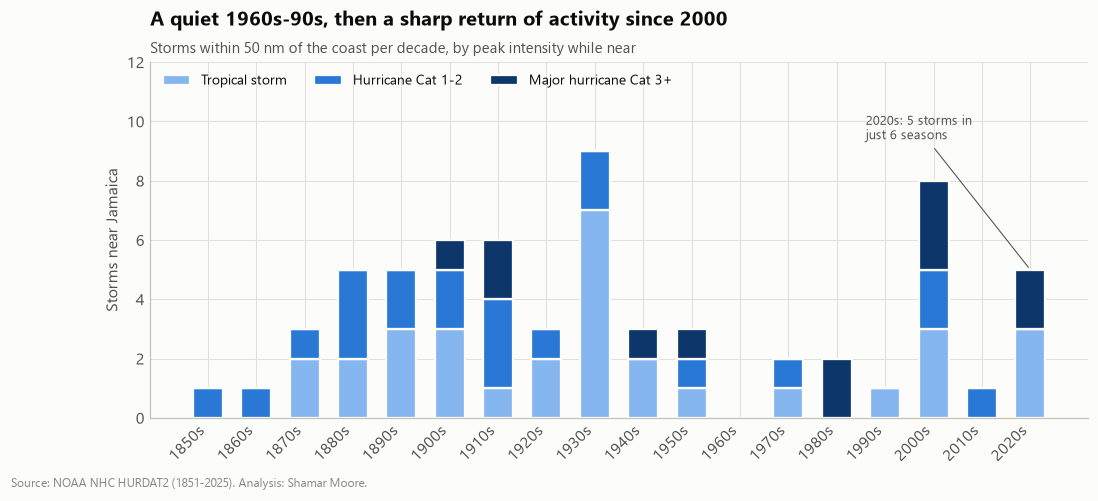

,ts_only,hu_minor,majors_near,total
decade,,,,
1950,1,1,1,3
1960,0,0,0,0
1970,1,1,0,2
1980,0,0,2,2
1990,1,0,0,1
2000,3,2,3,8
2010,0,1,0,1
2020,3,0,2,5


In [3]:
dec = seasons[seasons["year"] <= 2025].groupby("decade")[["ts_only", "hu_minor", "majors_near"]].sum()
dec = dec[dec.index >= 1850]

fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(dec))
bottom = np.zeros(len(dec))
for col, label, color in [("ts_only", "Tropical storm", P.INTENSITY["TS"]),
                          ("hu_minor", "Hurricane Cat 1-2", P.INTENSITY["Cat 2"]),
                          ("majors_near", "Major hurricane Cat 3+", P.INTENSITY["Cat 5"])]:
    ax.bar(x, dec[col], bottom=bottom, color=color, width=0.62, label=label, edgecolor=P.SURFACE, linewidth=1.5)
    bottom += dec[col].values
ax.set_xticks(x, [f"{d}s" for d in dec.index], rotation=45, ha="right")
ax.set_ylabel("Storms near Jamaica")
ax.legend(loc="upper left", fontsize=9, ncol=3)
ax.annotate(f"2020s: {bottom[-1]:.0f} storms in\njust 6 seasons", xy=(x[-1], bottom[-1]), xytext=(x[-1] - 3.4, bottom.max() + 0.4),
            fontsize=8.5, color=P.INK_2, arrowprops=dict(arrowstyle="-", color=P.INK_2, lw=0.7))
ax.set_ylim(0, bottom.max() + 3)
ax.set_title("A quiet 1960s-90s, then a sharp return of activity since 2000")
P.subtitle(ax, "Storms within 50 nm of the coast per decade, by peak intensity while near")
P.source_note(fig)
fig.savefig(config.FIGURES / "02_decadal_counts.png")
plt.show()
dec.assign(total=dec.sum(axis=1)).tail(8)

In [4]:
def poisson_trend(df, col, start):
    d = df[(df["year"] >= start) & (df["year"] <= 2025)].copy()
    d["t"] = (d["year"] - start) / 10  # per decade
    m = smf.glm(f"{col} ~ t", data=d, family=sm.families.Poisson()).fit()
    irr = np.exp(m.params["t"])
    lo, hi = np.exp(m.conf_int().loc["t"])
    return {"series": col, "from": start, "change_per_decade": f"{irr - 1:+.1%}",
            "95% CI": f"[{lo - 1:+.1%}, {hi - 1:+.1%}]", "p_value": round(m.pvalues["t"], 3)}

trend = pd.DataFrame([poisson_trend(seasons, c, s)
                      for c in ["storms_near", "hurricanes_near", "majors_near"]
                      for s in [1900, 1966]])
trend

,series,from,change_per_decade,95% CI,p_value
0,storms_near,1900,-4.4%,"[-11.6%, +3.3%]",0.254
1,storms_near,1966,+33.1%,"[+0.7%, +75.9%]",0.044
2,hurricanes_near,1900,-3.2%,"[-13.2%, +7.8%]",0.551
3,hurricanes_near,1966,+25.8%,"[-12.0%, +79.9%]",0.208
4,majors_near,1900,+7.1%,"[-8.6%, +25.5%]",0.394
5,majors_near,1966,+38.6%,"[-13.2%, +121.4%]",0.172


The starting year changes the answer, which is a useful reminder about trend-fitting:

* **From 1900:** no trend in storms, hurricanes or majors. The 1930s (9 storms) were busier than the 2000s (8).
* **From 1966 (satellite era):** storms near Jamaica rose about 33% per decade (p = 0.04). Hurricanes and majors point the same way but are too few to be significant (p ≥ 0.17).

The difference comes from the shape of the series. 1966-1999 was unusually quiet near Jamaica (about 0.15 storms per season), and 2000-2025 has been nearly 4× busier. That pattern matches the well-documented Atlantic multidecadal swing (a quiet phase from ~1970 to 1994, an active phase since 1995). It doesn't match a smooth climate trend. The practical point is that **the quiet decades many current plans and building stock were designed in were the exception, not the norm.**

In [5]:
p66 = seasons[(seasons["year"] >= 1966) & (seasons["year"] < 2000)]["storms_near"].mean()
p00 = seasons[(seasons["year"] >= 2000) & (seasons["year"] <= 2025)]["storms_near"].mean()
p20 = seasons[seasons["year"] >= 2020]["storms_near"].mean()
print(f"Storms near Jamaica per season: 1966-99 = {p66:.2f}, 2000-25 = {p00:.2f} ({p00/p66:.1f}x), 2020-25 = {p20:.2f}")

Storms near Jamaica per season: 1966-99 = 0.15, 2000-25 = 0.54 (3.7x), 2020-25 = 0.83


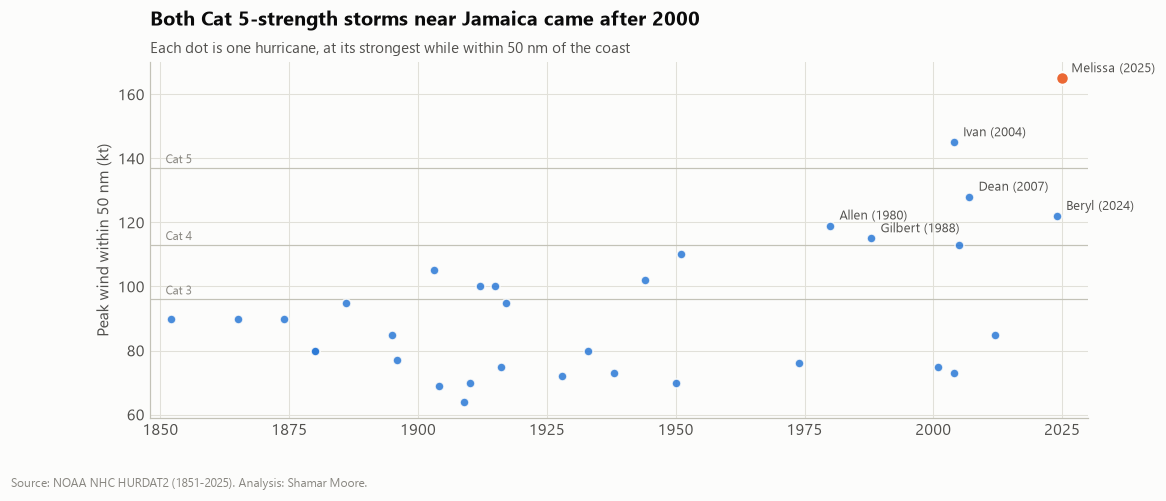

In [6]:
hu = near[near["is_hurricane_near"]].copy()
roll = (seasons.set_index("year")["max_wind_near_kt"].fillna(0).rolling(30, min_periods=20).max())

fig, ax = plt.subplots(figsize=(11, 4.2))
other = hu[hu["storm_label"] != "Melissa (2025)"]
ax.scatter(other["year"], other["max_wind_near_kt"], s=34, color=P.BLUE, alpha=0.85,
           edgecolor=P.SURFACE, linewidth=1, zorder=3, label="Hurricane near Jamaica")
m = hu[hu["storm_label"] == "Melissa (2025)"]
ax.scatter(m["year"], m["max_wind_near_kt"], s=70, color=P.ORANGE, edgecolor=P.SURFACE, linewidth=1.5, zorder=4)
for _, r in hu.nlargest(6, "max_wind_near_kt").iterrows():
    ax.annotate(r["storm_label"], (r["year"], r["max_wind_near_kt"]), xytext=(6, 4),
                textcoords="offset points", fontsize=8.5, color=P.INK_2)
for thr, lab in [(96, "Cat 3"), (113, "Cat 4"), (137, "Cat 5")]:
    ax.axhline(thr, color=P.AXIS, lw=0.8, zorder=1)
    ax.text(1851, thr + 1.5, lab, fontsize=8, color=P.MUTED)
ax.set_xlim(1848, 2030)
ax.set_ylabel("Peak wind within 50 nm (kt)")
ax.set_title("Both Cat 5-strength storms near Jamaica came after 2000")
P.subtitle(ax, "Each dot is one hurricane, at its strongest while within 50 nm of the coast")
P.source_note(fig)
fig.savefig(config.FIGURES / "02_intensity_over_time.png")
plt.show()

In [7]:
eras = pd.cut(hu["year"], [1850, 1949, 1999, 2025], labels=["1851-1949", "1950-1999", "2000-2025"])
summary = hu.groupby(eras, observed=True).agg(
    hurricanes=("storm_id", "count"),
    median_peak_kt=("max_wind_near_kt", "median"),
    share_major=("is_major_near", "mean"),
    share_rapid_intensification=("rapid_intensification", "mean"),
)
summary.style.format({"share_major": "{:.0%}", "share_rapid_intensification": "{:.0%}", "median_peak_kt": "{:.0f}"})

,hurricanes,median_peak_kt,share_major,share_rapid_intensification
year,,,,
1851-1949,20,82,20%,15%
1950-1999,5,110,60%,80%
2000-2025,8,118,62%,62%


In [8]:
from scipy.stats import mannwhitneyu
recent = hu.loc[hu["year"] >= 2000, "max_wind_near_kt"]
earlier = hu.loc[(hu["year"] >= 1950) & (hu["year"] < 2000), "max_wind_near_kt"]
stat, p = mannwhitneyu(recent, earlier, alternative="greater")
print(f"Median peak wind near Jamaica: 1950-99 = {earlier.median():.0f} kt (n={len(earlier)}), "
      f"2000-25 = {recent.median():.0f} kt (n={len(recent)}); one-sided Mann-Whitney p = {p:.3f}")

Median peak wind near Jamaica: 1950-99 = 110 kt (n=5), 2000-25 = 118 kt (n=8); one-sided Mann-Whitney p = 0.177


The **typical** hurricane near Jamaica isn't stronger than it used to be: the median peak wind is 110 kt in 1950-99 and 118 kt in 2000-25, and the test finds no difference (p = 0.18). The change is at the **top end**. Both storms that reached Cat 5 strength within 50 nm (Ivan 2004, Melissa 2025) came after 2000, and the share of hurricanes at Cat 4+ rose from 40% to 62%. With 5 and 8 hurricanes in the two periods this can't be called a trend, but it fits the projected shift toward more intense storms, and it's the tail that drives losses.

## 2 · ENSO

I use the Oceanic Niño Index for **Aug-Sep-Oct**, the core of the season. El Niño raises vertical wind shear over the Caribbean, which should suppress storms. La Niña lowers it.

In [9]:
modern = seasons[(seasons["year"] >= 1950) & (seasons["year"] <= 2025)].copy()
by_phase = modern.groupby("enso_phase").agg(
    seasons=("year", "count"),
    storms_per_season=("storms_near", "mean"),
    hurricanes_per_season=("hurricanes_near", "mean"),
    pct_seasons_with_hurricane=("hurricanes_near", lambda s: (s > 0).mean()),
).reindex(["La Nina", "Neutral", "El Nino"])

for col in ["storms_near", "hurricanes_near"]:
    glm = smf.glm(f"{col} ~ C(enso_phase, Treatment('El Nino'))", data=modern, family=sm.families.Poisson()).fit()
    rr = np.exp(glm.params.iloc[1])
    lo_, hi_ = np.exp(glm.conf_int().iloc[1])
    print(f"{col:16s} La Nina vs El Nino rate ratio = {rr:.2f}  (95% CI {lo_:.2f}-{hi_:.2f}, p = {glm.pvalues.iloc[1]:.3f})")
by_phase

storms_near      La Nina vs El Nino rate ratio = 1.11  (95% CI 0.32-3.84, p = 0.868)
hurricanes_near  La Nina vs El Nino rate ratio = 1.11  (95% CI 0.22-5.50, p = 0.897)


,seasons,storms_per_season,hurricanes_per_season,pct_seasons_with_hurricane
enso_phase,,,,
La Nina,18,0.277778,0.166667,0.166667
Neutral,38,0.315789,0.184211,0.184211
El Nino,20,0.250000,0.150000,0.100000


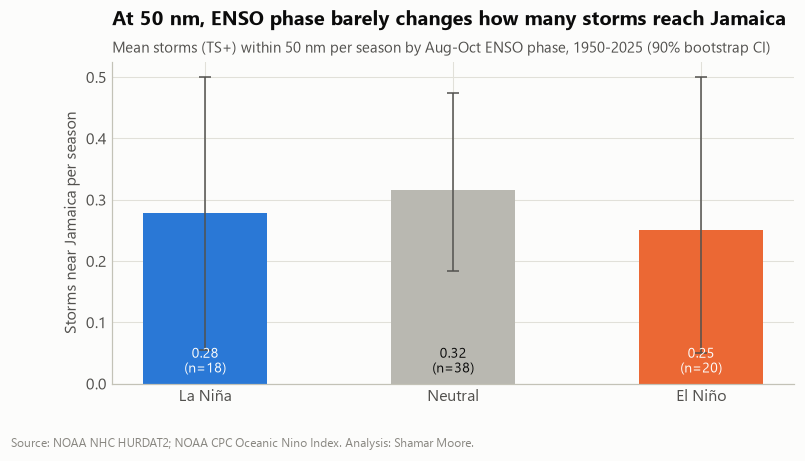

In [10]:
rng = np.random.default_rng(7)
boot = {ph: [rng.choice(g["storms_near"].values, len(g)).mean() for _ in range(5000)]
        for ph, g in modern.groupby("enso_phase")}
phases = ["La Nina", "Neutral", "El Nino"]
means = [modern.loc[modern["enso_phase"] == p, "storms_near"].mean() for p in phases]
lo = [np.percentile(boot[p], 5) for p in phases]
hi = [np.percentile(boot[p], 95) for p in phases]

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(3)
ax.bar(x, means, color=[P.ENSO[p] for p in phases], width=0.5)
ax.errorbar(x, means, yerr=[np.subtract(means, lo), np.subtract(hi, means)], fmt="none", ecolor=P.INK_2, capsize=4, lw=1)
for xi, mval, p in zip(x, means, phases):
    n = (modern["enso_phase"] == p).sum()
    ax.text(xi, 0.012, f"{mval:.2f}\n(n={n})", ha="center", va="bottom", fontsize=9, color=P.SURFACE if p != "Neutral" else P.INK)
ax.set_xticks(x, ["La Niña", "Neutral", "El Niño"])
ax.set_ylabel("Storms near Jamaica per season")
ax.set_title("At 50 nm, ENSO phase barely changes how many storms reach Jamaica")
P.subtitle(ax, "Mean storms (TS+) within 50 nm per season by Aug-Oct ENSO phase, 1950-2025 (90% bootstrap CI)")
P.source_note(fig, "Source: NOAA NHC HURDAT2; NOAA CPC Oceanic Nino Index. Analysis: Shamar Moore.")
fig.savefig(config.FIGURES / "02_enso_effect.png")
plt.show()

## 3 · Return periods

I treat seasonal counts as Poisson and estimate the annual rate λ for each threshold. The return period is 1/λ, and the chance of at least one event in a season is 1 − e^(−λ). I use 1900-2025 for hurricane-strength thresholds, where records near an inhabited island are reasonably complete, and 1966-2025 for all storms.

In [11]:
from scipy.stats import chi2

def rate_row(label, series, start):
    s = series[(seasons["year"] >= start) & (seasons["year"] <= 2025)]
    k, n = s.sum(), len(s)
    lam = k / n
    lo, hi = chi2.ppf(0.05, 2 * k) / (2 * n), chi2.ppf(0.95, 2 * k + 2) / (2 * n)  # exact Poisson 90% CI
    return {"event": label, "period": f"{start}-2025", "events": int(k), "annual_rate": lam,
            "return_period_yrs": 1 / lam, "rp_low": 1 / hi, "rp_high": 1 / lo if lo > 0 else np.inf,
            "p_any_in_season": 1 - np.exp(-lam), "p_any_in_10_yrs": 1 - np.exp(-10 * lam)}

cat4_plus = near[near["max_wind_near_kt"] >= 113].groupby("year").size().reindex(seasons["year"], fill_value=0).values
land_hu = storms[storms["jamaica_landfall"] & (storms["wind_at_closest_kt"] >= 64)].groupby("year").size().reindex(seasons["year"], fill_value=0).values

rp = pd.DataFrame([
    rate_row("Tropical storm or stronger", seasons["storms_near"], 1966),
    rate_row("Hurricane (Cat 1+)", seasons["hurricanes_near"], 1900),
    rate_row("Major hurricane (Cat 3+)", seasons["majors_near"], 1900),
    rate_row("Cat 4+", pd.Series(cat4_plus, index=seasons.index), 1900),
    rate_row("Hurricane landfall", pd.Series(land_hu, index=seasons.index), 1900),
])
rp.style.format({"annual_rate": "{:.3f}", "return_period_yrs": "{:.1f}", "rp_low": "{:.1f}", "rp_high": "{:.1f}",
                 "p_any_in_season": "{:.0%}", "p_any_in_10_yrs": "{:.0%}"})

,event,period,events,annual_rate,return_period_yrs,rp_low,rp_high,p_any_in_season,p_any_in_10_yrs
0,Tropical storm or stronger,1966-2025,19,0.317,3.2,2.2,4.8,27%,96%
1,Hurricane (Cat 1+),1900-2025,25,0.198,5.0,3.6,7.2,18%,86%
2,Major hurricane (Cat 3+),1900-2025,12,0.095,10.5,6.5,18.2,9%,61%
3,Cat 4+,1900-2025,7,0.056,18.0,9.6,38.4,5%,43%
4,Hurricane landfall,1900-2025,10,0.079,12.6,7.4,23.2,8%,55%


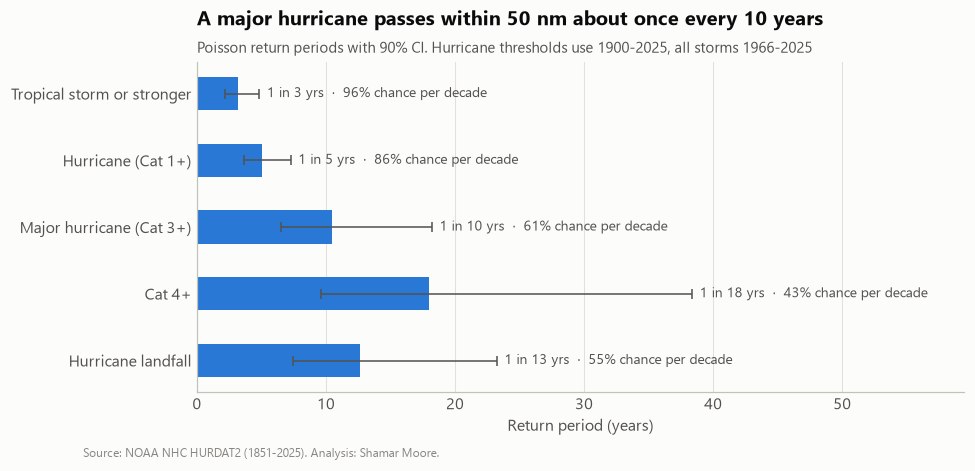

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.9))
y = np.arange(len(rp))[::-1]
ax.barh(y, rp["return_period_yrs"], color=P.BLUE, height=0.5)
ax.errorbar(rp["return_period_yrs"], y, xerr=[rp["return_period_yrs"] - rp["rp_low"], rp["rp_high"] - rp["return_period_yrs"]],
            fmt="none", ecolor=P.INK_2, capsize=3, lw=1)
for yi, (_, r) in zip(y, rp.iterrows()):
    ax.text(r["rp_high"] + 0.6, yi, f"1 in {r['return_period_yrs']:.0f} yrs  ·  {r['p_any_in_10_yrs']:.0%} chance per decade",
            va="center", fontsize=9, color=P.INK_2)
ax.set_yticks(y, rp["event"])
ax.set_xlabel("Return period (years)")
ax.set_xlim(0, rp["rp_high"].replace(np.inf, np.nan).max() * 1.55)
ax.grid(axis="y", visible=False)
major_rp = rp.loc[rp["event"].str.startswith("Major"), "return_period_yrs"].iat[0]
ax.set_title(f"A major hurricane passes within 50 nm about once every {major_rp:.0f} years")
P.subtitle(ax, "Poisson return periods with 90% CI. Hurricane thresholds use 1900-2025, all storms 1966-2025")
P.source_note(fig)
fig.savefig(config.FIGURES / "02_return_periods.png")
plt.show()

### Takeaways

* **Frequency:** no trend since 1900, but 2000-2025 has been nearly **4× busier** than the quiet 1966-1999 stretch, and the 2020s have already logged 5 storms in six seasons. Plans calibrated on the 1970s-90s underestimate today's exposure.
* **Intensity:** the typical hurricane isn't stronger, but the **tail is heavier**. Both Cat 5-strength storms near Jamaica (Ivan, Melissa) came after 2000.
* **ENSO doesn't show up at this range.** La Niña seasons averaged 0.28 storms within 50 nm against 0.25 for El Niño (rate ratio 1.11, p = 0.87). Inside a wider 100 nm ring the same test gave about 2.4× (p ≈ 0.08), but with 64 storms the signal isn't visible in close approaches. It isn't a basis for seasonal planning on its own.
* **Return periods:** a tropical storm or stronger within 50 nm in about one season in four, a hurricane about one season in five, a major hurricane about **once every 10 years** (roughly 3-in-5 odds per decade), and a hurricane landfall about once every 13 years.